# <span style="color:green"> Laboratorio di Simulazione Numerica </span>
## Tommaso Cardano Chiezzi


# Exercise 02 — Monte Carlo methods and Random Walks

## Indice

### 1. Exercise 02.1 — Monte Carlo integration
- 1.1 Uniform sampling
- 1.2 Importance sampling
- 1.3 Comparison of the two methods

### 2. Exercise 02.2 — 3D Random Walks
- 2.1 Random walk on a cubic lattice
- 2.2 Random walk in the continuum
- 2.3 Diffusive behavior
- 2.4 Fit with $f(N)=k\sqrt{N}$

### 3. Extra — Return to the origin for RW in 1D-2D-3D
# 1. Exercise 02.1 — Monte Carlo integration
In questo esercizio viene stimato numericamente l'integrale

$$
I =
\int_0^1
\frac{\pi}{2}
\cos\left(\frac{\pi x}{2}\right)\,dx.
$$

Il valore esatto è

$$
I =
\left[
\sin\left(\frac{\pi x}{2}\right)
\right]_0^1
= 1.
$$

La stima viene effettuata mediante due metodi Monte Carlo:

1. campionamento uniforme nell'intervallo $[0,1]$;
2. importance sampling: viene scelta una distribuzione il più possibile simile all'integranda (in questo caso ottenuta dallo sviluppo di Taylor al primo ordine dell'integranda, centrato in $x=1/2$) e viene campionata utilizzando il metodo della inversa della funzione cumulativa.

Per entrambi i metodi viene utilizzato il **data blocking** per ottenere la stima progressiva dell'integrale e della relativa incertezza statistica.
In particolare, per il calcolo dell'integrale, sono state effettuate $M = 10^6$ stime di $I$, divise in $N = 10^2$ blocchi.


## Uniform sampling

Per un integrale della forma

$$
I = \int_0^1 f(x)\,dx,
$$

campionando uniformemente $M$ punti $x_i \in [0,1]$, l'integrale può essere stimato tramite

$$
I \simeq
\frac{1}{M}
\sum_{i=1}^{M} f(x_i).
$$

In questo caso

$$
f(x) =
\frac{\pi}{2}
\cos\left(\frac{\pi x}{2}\right).
$$

Le variabili casuali vengono estratte direttamente dalla distribuzione uniforme

$$
p(x)=1,
\qquad 0\leq x\leq1.
$$

L'incertezza statistica della stima Monte Carlo diminuisce asintoticamente come

$$
\sigma_I \propto \frac{1}{\sqrt{M}}.
$$

## Importance sampling

Per ridurre la varianza della stima viene utilizzata una distribuzione di probabilità che approssima la forma dell'integranda.

Partendo da

$$
f(x) =
\frac{\pi}{2}
\cos\left(\frac{\pi x}{2}\right),
$$

viene considerato lo sviluppo di Taylor al primo ordine centrato nel punto

$$
x_0=\frac12.
$$

Si ha

$$
f\left(\frac12\right)
=
\frac{\pi}{2\sqrt{2}}
$$

e

$$
f'\left(\frac12\right)
=
-\frac{\pi^2}{4\sqrt{2}}.
$$

Lo sviluppo lineare è quindi

$$
f(x)
\simeq
\frac{\pi}{2\sqrt{2}}
\left[
1-\frac{\pi}{2}
\left(x-\frac12\right)
\right].
$$

Eliminando il prefattore costante e normalizzando nell'intervallo $[0,1]$, viene scelta la distribuzione

$$
p(x)=
1-\frac{\pi}{2}
\left(x-\frac12\right).
$$

La distribuzione è già normalizzata, infatti

$$
\int_0^1 p(x)\,dx = 1.
$$

Inoltre,

$$
p(0)=1+\frac{\pi}{4}>0
$$

e

$$
p(1)=1-\frac{\pi}{4}>0,
$$

quindi $p(x)$ è una densità di probabilità valida in tutto l'intervallo.

### Sampling della distribuzione

La densità utilizzata per l'importance sampling può essere riscritta come

$$
p(x)=
1+\frac{\pi}{4}
-\frac{\pi}{2}x.
$$

La funzione cumulativa associata è

$$
F(x)
=
\int_0^x p(t)\,dt
=
\left(1+\frac{\pi}{4}\right)x
-
\frac{\pi}{4}x^2.
$$

Ponendo

$$
r = F(x),
\qquad
r \sim U(0,1),
$$

la relazione può essere invertita analiticamente, ottenendo

$$
x=
\frac{2}{\pi}
\left[
1+\frac{\pi}{4}
-
\sqrt{
\left(1+\frac{\pi}{4}\right)^2-\pi r
}
\right].
$$

In questo modo un numero casuale uniforme $r$ viene trasformato in una variabile $x$ distribuita secondo $p(x)$.

Con l'importance sampling l'integrale viene riscritto come

$$
I =
\int_0^1
\frac{f(x)}{p(x)}
p(x)\,dx.
$$

Lo stimatore Monte Carlo diventa quindi

$$
I\simeq
\frac{1}{M}
\sum_{i=1}^{M}
\frac{f(x_i)}{p(x_i)},
\qquad
x_i \sim p(x).
$$

Se $p(x)$ approssima bene la forma dell'integranda, il rapporto $f(x)/p(x)$ presenta fluttuazioni inferiori e la varianza della stima viene ridotta rispetto al caso con campionamento uniforme.

In [2]:
import numpy as np
import matplotlib.pyplot as plt
# Vengono caricati i risultati prodotti dalla simulazione C++.


data = np.loadtxt("Esercizio_02.1\integral.txt")

n_blocks = data[:, 0]

integral_uniform = data[:, 1]
error_uniform = data[:, 2]

integral_importance = data[:, 3]
error_importance = data[:, 4]

exact_value = 1.0

print(f"Numero di blocchi: {len(n_blocks)}")
print()

print(
    f"Stima finale - Uniform sampling:    "
    f"{integral_uniform[-1]:.8f} ± {error_uniform[-1]:.8f}"
)

print(
    f"Stima finale - Importance sampling: "
    f"{integral_importance[-1]:.8f} ± {error_importance[-1]:.8f}"
)

Numero di blocchi: 100

Stima finale - Uniform sampling:    1.00023000 ± 0.00056568
Stima finale - Importance sampling: 0.99994500 ± 0.00013818


## Confronto tra integranda e distribuzione di importance sampling

La distribuzione utilizzata per l'importance sampling è stata costruita in modo da seguire approssimativamente l'andamento dell'integranda.

Vengono quindi confrontate le due funzioni

$$
f(x)=
\frac{\pi}{2}
\cos\left(\frac{\pi x}{2}\right)
$$

e

$$
p(x)=
1-\frac{\pi}{2}
\left(x-\frac12\right).
$$

Una maggiore somiglianza tra $p(x)$ e $f(x)$ permette di rendere il rapporto $f(x)/p(x)$ più uniforme e quindi di ridurre la varianza della stima Monte Carlo.

Entrambi i metodi devono convergere al valore esatto

$$
I=1.
$$

La principale differenza attesa riguarda l'ampiezza delle barre d'errore: l'importance sampling dovrebbe fornire una stima con varianza inferiore a parità di numero di campioni.

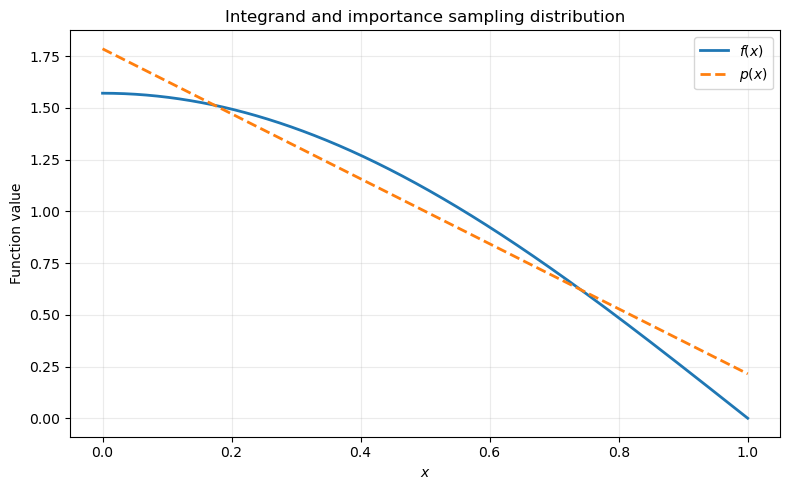

In [3]:
x = np.linspace(0.0, 1.0, 1000)

f = (np.pi / 2.0) * np.cos(np.pi * x / 2.0)

p = 1.0 - (np.pi / 2.0) * (x - 0.5)


plt.figure(figsize=(8, 5))

plt.plot(
    x,
    f,
    linewidth=2,
    label=r"$f(x)$"
)

plt.plot(
    x,
    p,
    linewidth=2,
    linestyle="--",
    label=r"$p(x)$"
)

plt.xlabel(r"$x$")
plt.ylabel("Function value")
plt.title("Integrand and importance sampling distribution")

plt.grid(alpha=0.25)
plt.legend()
plt.tight_layout()

plt.show()

Confronto tra il grafico dell'integranda e quello della distribuzione p(x)

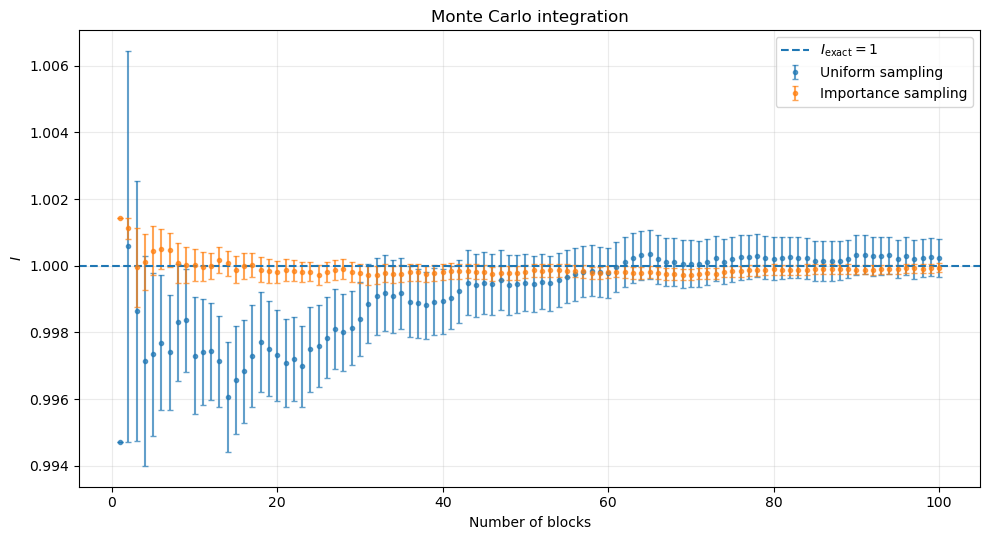

In [5]:
plt.figure(figsize=(10, 5.5))

plt.errorbar(
    n_blocks,
    integral_uniform,
    yerr=error_uniform,
    fmt="o",
    markersize=3,
    capsize=2,
    alpha=0.7,
    label="Uniform sampling"
)

plt.errorbar(
    n_blocks,
    integral_importance,
    yerr=error_importance,
    fmt="o",
    markersize=3,
    capsize=2,
    alpha=0.7,
    label="Importance sampling"
)

plt.axhline(
    exact_value,
    linestyle="--",
    linewidth=1.5,
    label=r"$I_{\mathrm{exact}} = 1$"
)

plt.xlabel("Number of blocks")
plt.ylabel(r"$I$")
plt.title("Monte Carlo integration")

plt.grid(alpha=0.25)
plt.legend()
plt.tight_layout()

plt.show()



Dal grafico si osserva che entrambi i metodi convergono verso il valore esatto

$$
I_{\mathrm{exact}} = 1.
$$

La principale differenza riguarda l'ampiezza delle barre d'errore. A parità di numero di blocchi, l'importance sampling presenta un'incertezza statistica sensibilmente inferiore rispetto al campionamento uniforme.

Questo comportamento è conseguenza della scelta di una distribuzione di campionamento $p(x)$ che segue meglio l'andamento dell'integranda. In questo modo il rapporto

$$
\frac{f(x)}{p(x)}
$$

presenta fluttuazioni minori rispetto alla funzione $f(x)$ campionata uniformemente, con una conseguente riduzione della varianza dell'estimatore.

Il metodo di importance sampling risulta quindi più efficiente: permette di ottenere una stima più precisa dell'integrale utilizzando lo stesso numero di campioni.

## Statistical uncertainty

Per confrontare l'efficienza dei due metodi viene considerata anche l'incertezza statistica progressiva.

L'errore della stima Monte Carlo è legato alla deviazione standard dell'estimatore secondo

$$
\sigma_I
\propto
\frac{\sigma}{\sqrt{M}}.
$$

A parità di numero di campioni $M$, una minore varianza produce quindi un'incertezza statistica inferiore.

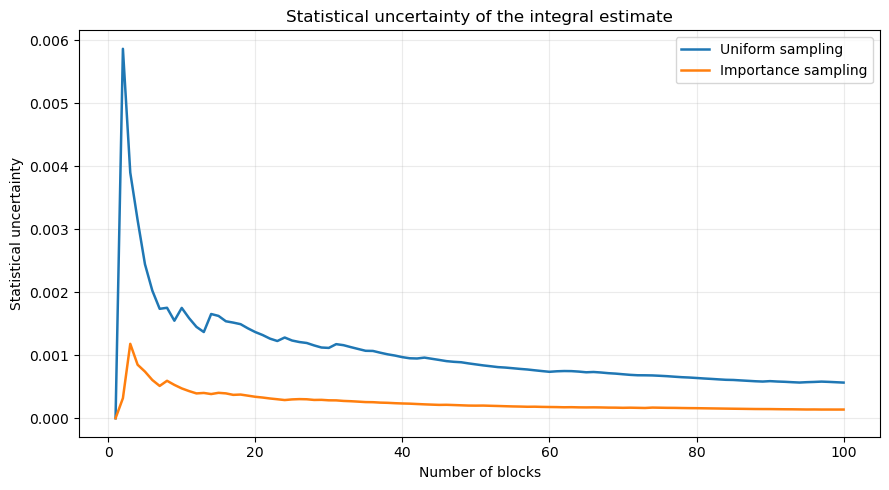

In [6]:
plt.figure(figsize=(9, 5))

plt.plot(
    n_blocks,
    error_uniform,
    linewidth=1.8,
    label="Uniform sampling"
)

plt.plot(
    n_blocks,
    error_importance,
    linewidth=1.8,
    label="Importance sampling"
)

plt.xlabel("Number of blocks")
plt.ylabel("Statistical uncertainty")
plt.title("Statistical uncertainty of the integral estimate")

plt.grid(alpha=0.25)
plt.legend()
plt.tight_layout()

plt.show()

In [7]:
# Vengono confrontati i risultati finali ottenuti con i due metodi.

final_uniform = integral_uniform[-1]
final_importance = integral_importance[-1]

final_error_uniform = error_uniform[-1]
final_error_importance = error_importance[-1]


# Il rapporto tra gli errori fornisce una misura del miglioramento
# ottenuto con l'importance sampling.

error_reduction = final_error_uniform / final_error_importance

# Il quadrato del rapporto tra gli errori fornisce una stima
# della riduzione della varianza.

variance_reduction = error_reduction**2


print("Final results")
print("--------------------------------")

print(
    f"Uniform sampling:    "
    f"{final_uniform:.8f} ± {final_error_uniform:.8f}"
)

print(
    f"Importance sampling: "
    f"{final_importance:.8f} ± {final_error_importance:.8f}"
)

print()

print(
    f"Error reduction factor:    {error_reduction:.2f}"
)

print(
    f"Variance reduction factor: {variance_reduction:.2f}"
)

Final results
--------------------------------
Uniform sampling:    1.00023000 ± 0.00056568
Importance sampling: 0.99994500 ± 0.00013818

Error reduction factor:    4.09
Variance reduction factor: 16.76



Per concludere, l'integrale

$$
I=
\int_0^1
\frac{\pi}{2}
\cos\left(\frac{\pi x}{2}\right)\,dx
$$

è stato stimato mediante Monte Carlo utilizzando sia un campionamento uniforme sia un importance sampling.

Entrambe le stime convergono al valore esatto

$$
I=1
$$

entro le rispettive incertezze statistiche.

Nel metodo di importance sampling viene utilizzata la distribuzione

$$
p(x)=
1-\frac{\pi}{2}
\left(x-\frac12\right),
$$

costruita a partire dallo sviluppo di Taylor al primo ordine dell'integranda centrato in $x=1/2$.

Il confronto mostra che l'importance sampling riduce l'incertezza statistica rispetto al campionamento uniforme a parità di numero di campioni, grazie alla minore varianza dell'estimatore.

# Exercise 02.2 — 3D Random Walks

In questo esercizio vengono simulati due random walk tridimensionali, entrambi con posizione iniziale nell'origine.

Nel primo caso il walker si muove su un **reticolo cubico** con passo $a=1$. A ogni step viene scelta casualmente una delle sei possibili direzioni

$$
\pm x,\qquad \pm y,\qquad \pm z.
$$

Nel secondo caso il walker si muove nel **continuo**, sempre con passo di lunghezza $a=1$, ma lungo una direzione casuale uniformemente distribuita nello spazio.

La simulazione viene ripetuta $M=10^4$ volte e, per ogni numero di step $N$, viene stimata la distanza quadratica media dalla posizione iniziale:

$$
\sqrt{\left\langle |\vec r_N|^2 \right\rangle}.
$$

Il metodo del **data blocking** viene utilizzato per determinare la media e la relativa incertezza statistica.

## Random walk in the continuum

Per il random walk nel continuo, una direzione nello spazio viene descritta dagli angoli sferici $\theta$ e $\phi$:

$$
\Delta x = a\sin\theta\cos\phi,
$$

$$
\Delta y = a\sin\theta\sin\phi,
$$

$$
\Delta z = a\cos\theta.
$$

Per ottenere una distribuzione uniforme delle direzioni sull'angolo solido, $\phi$ può essere campionato uniformemente nell'intervallo $[0,2\pi)$:

$$
\phi = 2\pi r_1,
\qquad r_1\sim U(0,1).
$$

L'elemento di angolo solido è invece

$$
d\Omega = \sin\theta\,d\theta\,d\phi,
$$

quindi $\theta$ deve essere distribuito secondo

$$
p(\theta)=\frac{1}{2}\sin\theta.
$$

La funzione cumulativa è

$$
F(\theta)
=
\int_0^\theta
\frac{1}{2}\sin\theta'\,d\theta'
=
\frac{1}{2}(1-\cos\theta).
$$

Utilizzando il metodo dell'inversione si ottiene

$$
\theta=\arccos(1-2r_2),
\qquad r_2\sim U(0,1).
$$

## Diffusive behavior

Dopo $N$ passi, la posizione del walker è

$$
\vec r_N = \sum_{i=1}^{N}\Delta\vec r_i.
$$

La distanza quadratica dall'origine è quindi

$$
r_N^2
=
\left(
\sum_{i=1}^{N}\Delta\vec r_i
\right)^2
=
\sum_{i=1}^{N}|\Delta\vec r_i|^2
+
2\sum_{i<j}
\Delta\vec r_i\cdot\Delta\vec r_j.
$$

Ogni passo ha lunghezza costante $a$, quindi

$$
|\Delta\vec r_i|^2=a^2.
$$

Inoltre, i diversi passi sono indipendenti e non esiste una direzione privilegiata. Mediando su molti random walk, i termini incrociati si annullano:

$$
\left\langle
\Delta\vec r_i\cdot\Delta\vec r_j
\right\rangle=0
\qquad i\neq j.
$$

Si ottiene quindi

$$
\left\langle r_N^2\right\rangle
=
Na^2,
$$

e dunque

$$
\boxed{
\sqrt{\left\langle r_N^2\right\rangle}
=
a\sqrt{N}
}.
$$

Nel caso considerato $a=1$, per cui il comportamento atteso è

$$
\sqrt{\left\langle r_N^2\right\rangle}
=
\sqrt{N}.
$$

Una dipendenza proporzionale a $\sqrt N$ è caratteristica di un processo diffusivo.

In [28]:
import numpy as np
import matplotlib.pyplot as plt

from scipy.optimize import curve_fit
# Vengono caricati i risultati prodotti dalla simulazione C++.


data = np.loadtxt("Esercizio_02.2/random_walk.txt")

steps = data[:, 0]

rms_lattice = data[:, 1]
error_lattice = data[:, 2]

rms_continuum = data[:, 3]
error_continuum = data[:, 4]


print(f"Numero massimo di step: {int(steps[-1])}")
print()

print(
    f"Reticolo a N = {int(steps[-1])}: "
    f"{rms_lattice[-1]:.6f} ± {error_lattice[-1]:.6f}"
)

print(
    f"Continuo a N = {int(steps[-1])}: "
    f"{rms_continuum[-1]:.6f} ± {error_continuum[-1]:.6f}"
)

Numero massimo di step: 100

Reticolo a N = 100: 10.052900 ± 0.044454
Continuo a N = 100: 9.911010 ± 0.038905


## Results

Viene riportata la quantità

$$
\sqrt{\left\langle r_N^2\right\rangle}
$$

in funzione del numero di step $N$ per entrambi i random walk.

Le barre d'errore rappresentano l'incertezza statistica ottenuta tramite il data blocking.

Per confronto viene riportato anche il comportamento teorico atteso per $a=1$:

$$
\sqrt{\left\langle r_N^2\right\rangle}=\sqrt{N}.
$$

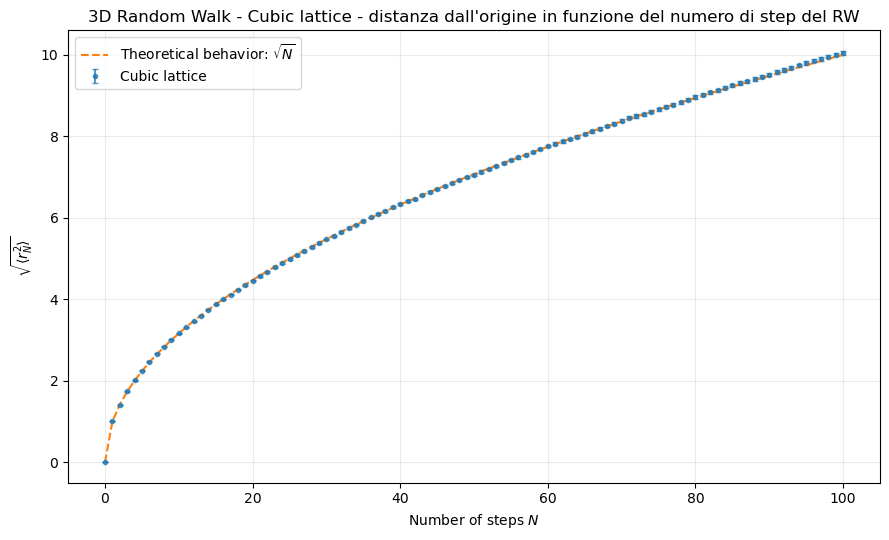

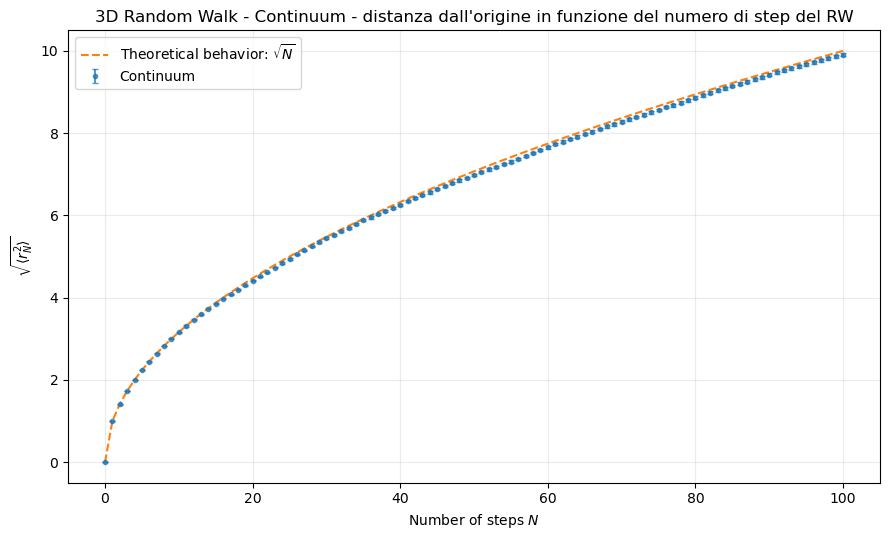

In [32]:
plt.figure(figsize=(9, 5.5))

plt.errorbar(
    steps,
    rms_lattice,
    yerr=error_lattice,
    fmt="o",
    markersize=3,
    capsize=2,
    alpha=0.75,
    label="Cubic lattice"
)

plt.plot(
    steps,
    np.sqrt(steps),
    linestyle="--",
    linewidth=1.5,
    label=r"Theoretical behavior: $\sqrt{N}$"
)

plt.xlabel("Number of steps $N$")
plt.ylabel(r"$\sqrt{\langle r_N^2 \rangle}$")
plt.title("3D Random Walk - Cubic lattice - distanza dall'origine in funzione del numero di step del RW")

plt.grid(alpha=0.25)
plt.legend()
plt.tight_layout()





plt.figure(figsize=(9, 5.5))

plt.errorbar(
    steps,
    rms_continuum,
    yerr=error_continuum,
    fmt="o",
    markersize=3,
    capsize=2,
    alpha=0.75,
    label="Continuum"
)

plt.plot(
    steps,
    np.sqrt(steps),
    linestyle="--",
    linewidth=1.5,
    label=r"Theoretical behavior: $\sqrt{N}$"
)

plt.xlabel("Number of steps $N$")
plt.ylabel(r"$\sqrt{\langle r_N^2 \rangle}$")
plt.title("3D Random Walk - Continuum - distanza dall'origine in funzione del numero di step del RW")

plt.grid(alpha=0.25)
plt.legend()
plt.tight_layout()

plt.show()



## Fit with the diffusive law

Per verificare quantitativamente il comportamento diffusivo, entrambi i risultati vengono interpolati con la funzione

$$
f(N)=k\sqrt{N}.
$$

Per un random walk con passo di lunghezza $a=1$, il valore teorico atteso è

$$
k=1.
$$

Il punto $N=0$ viene escluso dal fit.

Fit results
--------------------------------
Cubic lattice: k = 1.000517 ± 0.000408
Continuum:     k = 0.991243 ± 0.000389


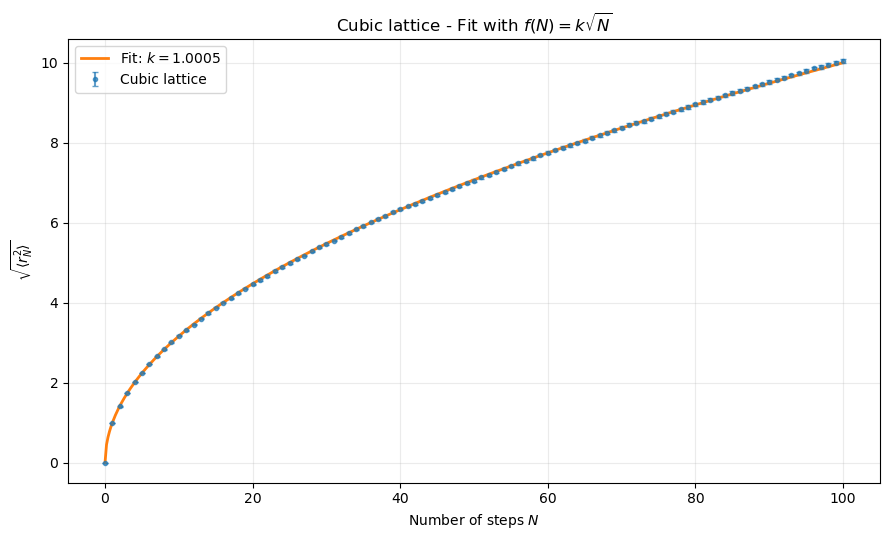

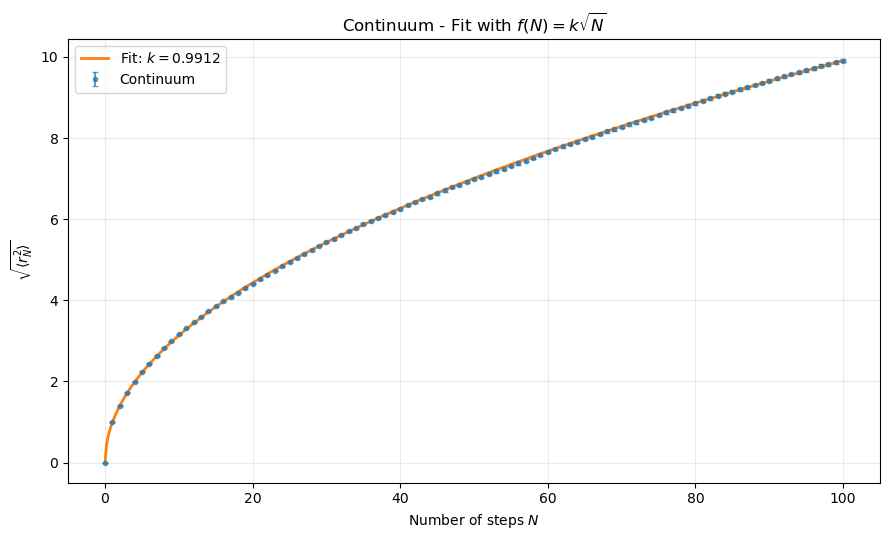

In [37]:
# Funzione utilizzata per il fit
def diffusive_law(N, k):
    return k * np.sqrt(N)


# Il punto N = 0 viene escluso.
# Vengono inoltre utilizzati solo punti con errore positivo.

mask_lattice = (steps > 0) & (error_lattice > 0)
mask_continuum = (steps > 0) & (error_continuum > 0)


# Fit del random walk sul reticolo
popt_lattice, pcov_lattice = curve_fit(
    diffusive_law,
    steps[mask_lattice],
    rms_lattice[mask_lattice],
    sigma=error_lattice[mask_lattice],
    absolute_sigma=True
)

k_lattice = popt_lattice[0]
k_lattice_err = np.sqrt(pcov_lattice[0, 0])


# Fit del random walk nel continuo
popt_continuum, pcov_continuum = curve_fit(
    diffusive_law,
    steps[mask_continuum],
    rms_continuum[mask_continuum],
    sigma=error_continuum[mask_continuum],
    absolute_sigma=True
)

k_continuum = popt_continuum[0]
k_continuum_err = np.sqrt(pcov_continuum[0, 0])


print("Fit results")
print("--------------------------------")

print(
    f"Cubic lattice: k = "
    f"{k_lattice:.6f} ± {k_lattice_err:.6f}"
)

print(
    f"Continuum:     k = "
    f"{k_continuum:.6f} ± {k_continuum_err:.6f}"
)

N_fit = np.linspace(0, steps[-1], 500)


# ------------------------------------------------------------
# Fit del random walk sul reticolo cubico
# ------------------------------------------------------------

plt.figure(figsize=(9, 5.5))

plt.errorbar(
    steps,
    rms_lattice,
    yerr=error_lattice,
    fmt="o",
    markersize=3,
    capsize=2,
    alpha=0.7,
    label="Cubic lattice"
)

plt.plot(
    N_fit,
    diffusive_law(N_fit, k_lattice),
    linewidth=2,
    label=fr"Fit: $k={k_lattice:.4f}$"
)

plt.xlabel("Number of steps $N$")
plt.ylabel(r"$\sqrt{\langle r_N^2 \rangle}$")
plt.title(r"Cubic lattice - Fit with $f(N)=k\sqrt{N}$")

plt.grid(alpha=0.25)
plt.legend()
plt.tight_layout()

plt.show()


# ------------------------------------------------------------
# Fit del random walk nel continuo
# ------------------------------------------------------------

plt.figure(figsize=(9, 5.5))

plt.errorbar(
    steps,
    rms_continuum,
    yerr=error_continuum,
    fmt="o",
    markersize=3,
    capsize=2,
    alpha=0.7,
    label="Continuum"
)

plt.plot(
    N_fit,
    diffusive_law(N_fit, k_continuum),
    linewidth=2,
    label=fr"Fit: $k={k_continuum:.4f}$"
)

plt.xlabel("Number of steps $N$")
plt.ylabel(r"$\sqrt{\langle r_N^2 \rangle}$")
plt.title(r"Continuum - Fit with $f(N)=k\sqrt{N}$")

plt.grid(alpha=0.25)
plt.legend()
plt.tight_layout()

plt.show()

## Conclusioni

Sono stati simulati due random walk tridimensionali con passo di lunghezza $a=1$: uno su un reticolo cubico e uno nel continuo.

In entrambi i casi la distanza quadratica media cresce linearmente con il numero di step,

$$
\left\langle r_N^2\right\rangle\propto N,
$$

e di conseguenza la distanza RMS segue la legge

$$
\sqrt{\left\langle r_N^2\right\rangle}
\propto
\sqrt{N}.
$$

Il fit con

$$
f(N)=k\sqrt{N}
$$

fornisce per entrambi i random walk un valore di $k$ compatibile con il valore teorico atteso $k=1$ entro le incertezze statistiche.

Il comportamento osservato è quindi compatibile con un processo diffusivo.

Nonostante le differenze microscopiche tra il moto sul reticolo e quello nel continuo, i due modelli mostrano lo stesso comportamento a grandi scale.

# 3. Extra — Return probability in 1D, 2D and 3D

Come estensione della simulazione, è interessante studiare la probabilità cumulativa di ritorno all'origine per random walk su reticolo in una, due e tre dimensioni.

Per ogni walker viene considerata la probabilità di essere ritornato almeno una volta all'origine entro lo step $N$:

$$
P_{\mathrm{return}}(N)
=
P(T_{\mathrm{return}}\leq N).
$$

La simulazione viene eseguita separatamente in $d=1$, $d=2$ e $d=3$, utilizzando lo stesso numero di random walk e lo stesso numero massimo di step.

In tutti i casi il punto iniziale $N=0$ non viene considerato come un ritorno.

Il metodo del data blocking viene utilizzato per stimare la probabilità cumulativa e la relativa incertezza statistica.

In [44]:
# Vengono caricati i risultati della parte extra della simulazione C++.

return_data = np.loadtxt("Esercizio_02.2/return_probability.txt")

return_steps = return_data[:, 0]

p_return_1d = return_data[:, 1]
error_return_1d = return_data[:, 2]

p_return_2d = return_data[:, 3]
error_return_2d = return_data[:, 4]

p_return_3d = return_data[:, 5]
error_return_3d = return_data[:, 6]


print(f"Numero massimo di step: {int(return_steps[-1])}")
print()

print(
    f"1D: P_return = "
    f"{p_return_1d[-1]:.6f} ± {error_return_1d[-1]:.6f}"
)

print(
    f"2D: P_return = "
    f"{p_return_2d[-1]:.6f} ± {error_return_2d[-1]:.6f}"
)

print(
    f"3D: P_return = "
    f"{p_return_3d[-1]:.6f} ± {error_return_3d[-1]:.6f}"
)

Numero massimo di step: 2000

1D: P_return = 0.982460 ± 0.000597
2D: P_return = 0.702520 ± 0.001929
3D: P_return = 0.334000 ± 0.001818


## Comparison of return probabilities

Il comportamento asintotico della probabilità di ritorno dipende dalla dimensionalità del random walk.

In una e due dimensioni il random walk semplice è **ricorrente**, quindi

$$
P_{\mathrm{return}}(\infty)=1.
$$

Questo significa che, lasciando evolvere il walker per un numero arbitrariamente grande di step, la probabilità di ritornare almeno una volta all'origine tende a $1$.

In tre dimensioni, invece, il random walk è **transiente**:

$$
P_{\mathrm{return}}(\infty)<1.
$$

Per il reticolo cubico tridimensionale il valore limite noto è circa

$$
P_{\mathrm{return}}(\infty)\simeq0.3405.
$$

Il confronto numerico permette quindi di osservare direttamente il diverso comportamento tra $d=1$, $d=2$ e $d=3$.

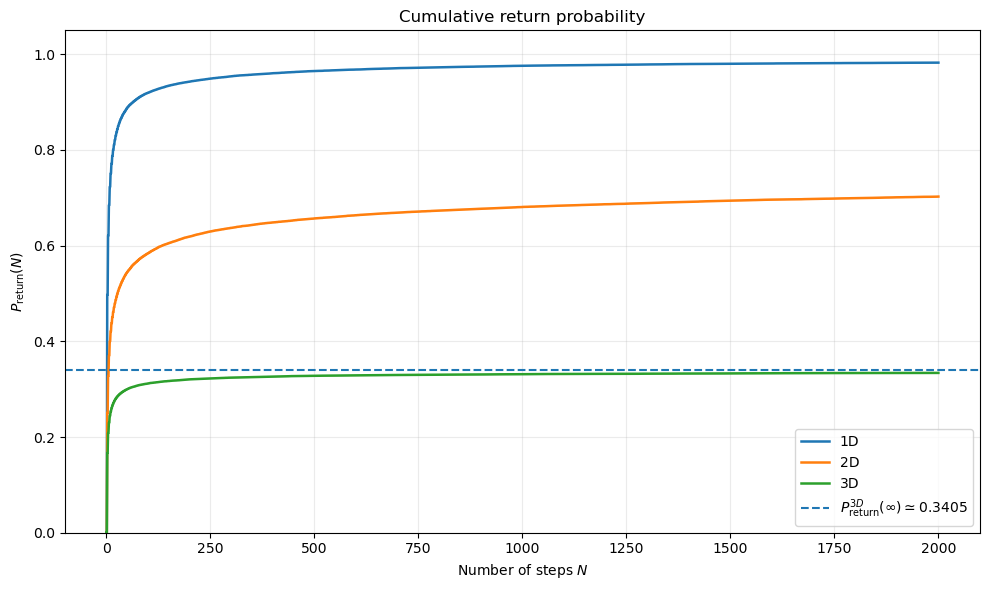

In [46]:
p_return_3d_theoretical = 0.3405


plt.figure(figsize=(10, 6))

# Random walk 1D
plt.plot(
    return_steps,
    p_return_1d,
    linewidth=1.8,
    label="1D"
)

plt.fill_between(
    return_steps,
    np.maximum(0.0, p_return_1d - error_return_1d),
    np.minimum(1.0, p_return_1d + error_return_1d),
    alpha=0.15
)


# Random walk 2D
plt.plot(
    return_steps,
    p_return_2d,
    linewidth=1.8,
    label="2D"
)

plt.fill_between(
    return_steps,
    np.maximum(0.0, p_return_2d - error_return_2d),
    np.minimum(1.0, p_return_2d + error_return_2d),
    alpha=0.15
)


# Random walk 3D
plt.plot(
    return_steps,
    p_return_3d,
    linewidth=1.8,
    label="3D"
)

plt.fill_between(
    return_steps,
    np.maximum(0.0, p_return_3d - error_return_3d),
    np.minimum(1.0, p_return_3d + error_return_3d),
    alpha=0.15
)


# Limite teorico del random walk 3D
plt.axhline(
    p_return_3d_theoretical,
    linestyle="--",
    linewidth=1.5,
    label=r"$P_{\mathrm{return}}^{3D}(\infty)\simeq0.3405$"
)


plt.xlabel("Number of steps $N$")
plt.ylabel(r"$P_{\mathrm{return}}(N)$")
plt.title("Cumulative return probability")

plt.ylim(0, 1.05)

plt.grid(alpha=0.25)
plt.legend()
plt.tight_layout()

plt.show()

Dal confronto emerge una chiara dipendenza dalla dimensionalità.

Nel caso unidimensionale la probabilità cumulativa di ritorno cresce rapidamente verso $1$.

In due dimensioni la probabilità continua anch'essa a crescere verso $1$, ma la convergenza è sensibilmente più lenta.

In tre dimensioni, invece, la curva tende progressivamente a saturare su un valore inferiore a $1$, in accordo con il carattere transiente del random walk tridimensionale.

Il comportamento osservato è quindi compatibile con

$$
P_{\mathrm{return}}(\infty)=1
\qquad
\text{per }d=1,2,
$$

mentre

$$
P_{\mathrm{return}}(\infty)\simeq0.3405
\qquad
\text{per }d=3.
$$

Il valore ottenuto numericamente a un numero finito di step non coincide necessariamente con il limite asintotico, in particolare nel caso bidimensionale, dove la convergenza verso $1$ è molto lenta.